# Lab 1 · Teaching a network to remove noise

**Lecture 3 · Diffusion models — practical session, part 1 of 3**

Duration: about 1 h 45 min · Runs on a normal computer: no GPU needed.

In the lecture we saw how a diffusion model learns to turn random noise into an image. In this lab you will build the whole mechanism yourself on a very small example, and you will reproduce several figures of the lecture with your own code.


**How to work**

- Run the cells in order, from top to bottom (click a cell, then press **Shift + Enter**). If something goes wrong, use *Runtime > Restart session and run all*.
- When a cell is marked **Predict**, first write what you expect, then run the next cell and compare. Your prediction does not need to be correct: comparing is what matters.
- Write your answers in the cells marked **Your answer** (double-click the cell to edit it). A few sentences are enough.
- You do not need to understand every line of code. The important ideas are explained in the text. The code is shown so that you can see that nothing is hidden.



## 0 · Setup

Run this cell once. It loads the libraries and fixes the random seeds, so that everyone gets the same results.

In [17]:
import math, time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from skimage import data, color, transform

torch.manual_seed(0)
np.random.seed(0)

BLUE, PINK, DARK, GREY = '#278DBD', '#E2336B', '#25313A', '#73818A'

# The noise schedule of the DDPM paper: 1000 small steps, decided once and for all before training.
T = 1000
betas = torch.linspace(1e-4, 0.02, T)
alpha_bar = torch.cumprod(1 - betas, dim=0)

def level_to_step(level):
    """Convert a noise level between 0 (clean) and 1 (pure noise) into one of the 1000 steps."""
    return int(round(level * (T - 1)))

print('Ready.')

Ready.


## 1 · Warm-up: make an image disappear


Destroying an image is easy. We **fade** the image a little and **mix in random noise**. How much we do this is set by a **noise level** between 0 % (the clean image) and 100 % (pure noise).

The function `add_noise` below does exactly this, with the same recipe as in the lecture (the DDPM schedule with 1000 steps). You only need to choose the noise level.

We start with an 8 × 8 handwritten digit, the same kind of image as in the lecture.

In [18]:
digits = load_digits()
seven = torch.tensor(digits.images[7], dtype=torch.float32) / 16 * 2 - 1   # pixel values between -1 and 1

def add_noise(image, level, seed=0):
    """Fade the image and mix in random noise. level: 0 = clean image, 1 = pure noise."""
    generator = torch.Generator().manual_seed(seed)
    noise = torch.randn(image.shape, generator=generator)
    a = alpha_bar[level_to_step(level)]
    return a.sqrt() * image + (1 - a).sqrt() * noise

def show_images(images, titles, size=2.2):
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size + 0.4))
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img, cmap='gray', vmin=-1, vmax=1)
        ax.set_title(title, fontsize=10)
        ax.axis('off')
    plt.show()

**Predict.** Below, the same digit is shown at noise levels 0 %, 10 %, 20 %, 30 %, 40 %, 60 % and 100 %. From which level do you think you will no longer recognise the digit?

**Your answer:**

* I think it will not be possible to identifie the number when the level of noise reach 60%

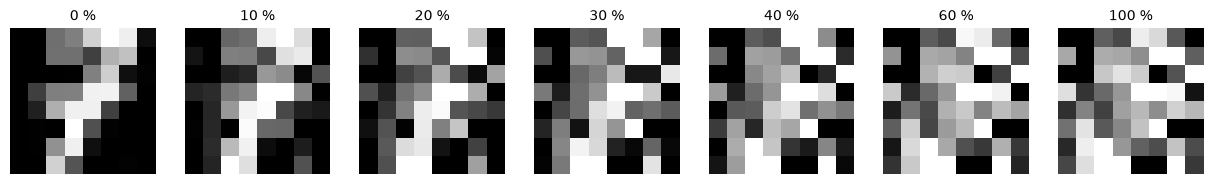

In [19]:
levels = [0, 0.1, 0.2, 0.3, 0.4, 0.6, 1.0]
show_images([add_noise(seven, lv) for lv in levels], [f'{int(lv * 100)} %' for lv in levels])

**Question 1.** From which noise level can you no longer recognise the 7? Was your prediction right?

**Your answer:**

* At 60% of noise, i can not see the 7 again, so my prediction was right 

Now the same experiment with a photo, which has many more pixels (about 67 000 instead of 64).

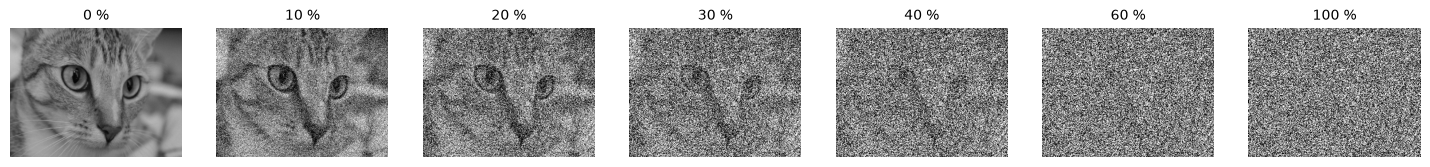

In [20]:
photo = transform.resize(color.rgb2gray(data.chelsea()), (225, 300), anti_aliasing=True)
photo = torch.tensor(photo, dtype=torch.float32) * 2 - 1
show_images([add_noise(photo, lv) for lv in levels], [f'{int(lv * 100)} %' for lv in levels], size=2.6)

**Question 2.** Do you lose the photo at the same noise level as the small digit? Why could it be different?

**Your answer:**

* Yes i'm still loosing the ohoto when the noise level get to 60 %, but it could be different because of the shape and the edge of the image

### Same image, different noise

In the lecture, the noise we add is **drawn at random** each time. Below, the same digit gets the same noise level (30 %) but four different random draws.

Each of these noisy images is a new **training example**, and we know exactly which noise was added to it, because we drew it ourselves. That noise is the **answer key** that the network will have to guess (slide 12).

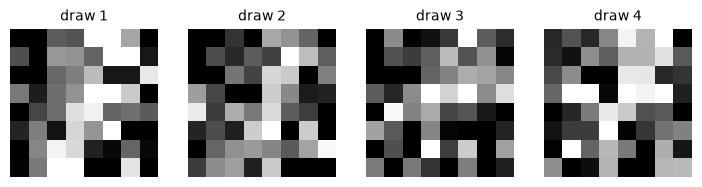

In [21]:
show_images([add_noise(seven, 0.3, seed=s) for s in range(4)], [f'draw {s + 1}' for s in range(4)])

**Question 3.** Why can we create as many training examples as we want from a single image, without anybody labelling anything?

**Your answer:**

* Because we can add a random noise to the image that’s different each time. Since we know the noise we added, it automatically serves as the expected output to train the network: no manual annotation is needed.

### Go further (optional): the recipe behind `add_noise`

In words: **noisy image = fading factor × image + noise factor × random noise.**
Both factors are read from a fixed table of 1000 values, decided before training. As the noise level goes up, the fading factor goes down and the noise factor goes up. Run the cell to see a few values.

In [22]:
for lv in [0, 0.1, 0.25, 0.5, 0.75, 1.0]:
    a = alpha_bar[level_to_step(lv)]
    print(f'noise level {int(lv * 100):3d} %   fading factor {a.sqrt():.2f}   noise factor {(1 - a).sqrt():.2f}')

noise level   0 %   fading factor 1.00   noise factor 0.01
noise level  10 %   fading factor 0.95   noise factor 0.32
noise level  25 %   fading factor 0.72   noise factor 0.69
noise level  50 %   fading factor 0.28   noise factor 0.96
noise level  75 %   fading factor 0.06   noise factor 1.00
noise level 100 %   fading factor 0.01   noise factor 1.00


## 2 · A tiny world with two kinds of data

A real image is a list of numbers (one per pixel), so it is a point in a space with thousands of dimensions. We cannot draw that. To be able to **see** everything that happens, we now use a world where each example is made of only **2 numbers**: every example is a point in a plane.

Our world contains two kinds of data: **blue** points and **pink** points. Think of them as two kinds of images, for example cats and chairs.

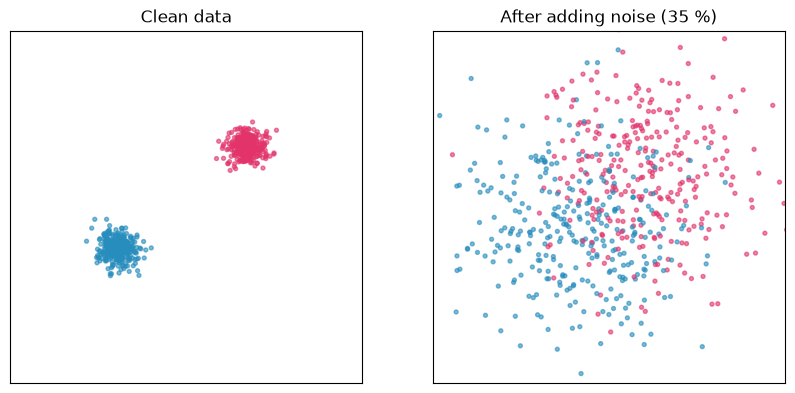

In [23]:
BLUE_CENTER = torch.tensor([-1.0, -0.6])
PINK_CENTER = torch.tensor([0.9, 0.9])
SPREAD = 0.15

def sample_real_points(n, seed=None):
    """Draw n real examples: half blue, half pink. Returns the points and their kind (0 = blue, 1 = pink)."""
    generator = torch.Generator().manual_seed(seed) if seed is not None else None
    kind = torch.randint(0, 2, (n,), generator=generator)
    centers = torch.where(kind[:, None] == 0, BLUE_CENTER, PINK_CENTER)
    return centers + SPREAD * torch.randn(n, 2, generator=generator), kind

def kind_colors(kind):
    return [BLUE if k == 0 else PINK for k in kind]

def setup_axes(ax, title, lim=2.6):
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect('equal')
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title)

real_points, real_kind = sample_real_points(600, seed=1)
noisy_points = add_noise(real_points, 0.35, seed=2)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
axes[0].scatter(real_points[:, 0], real_points[:, 1], s=8, c=kind_colors(real_kind), alpha=0.6)
setup_axes(axes[0], 'Clean data')
axes[1].scatter(noisy_points[:, 0], noisy_points[:, 1], s=8, c=kind_colors(real_kind), alpha=0.6)
setup_axes(axes[1], 'After adding noise (35 %)')
plt.show()

On the right, each noisy point keeps the colour of the group it came from, but the network will **not** see these colours: it only sees the position.

**Question 4.** Look at a noisy point in the middle, between the two groups. Could you tell whether it came from the blue or the pink group? What does this mean for a network that must guess the noise that was added?

**Your answer:**

* No. A point in the overlap could have come from either the blue or pink group. The added noise cannot always be uniquely identified from the noisy point;

## 3 · Train a network to guess the noise



The training recipe has four steps, repeated thousands of times:

1. Take a real example (a blue or pink point).
2. Choose a noise level at random.
3. Add noise that we draw ourselves, so we know it.
4. Give the noisy point **and** the noise level to the network, ask it to guess the noise, measure how wrong it is (the average squared error), and adjust the network a little.

This is exactly Algorithm 1 of the DDPM paper (slide 18). The network never sees the clean point: it only sees the noisy point and the noise level.

The network itself is a small neural network: it takes 2 numbers and the noise level, and returns 2 numbers (its guess of the noise). You can skip the details of the next cell.

In [24]:
class NoiseGuesser(nn.Module):
    """Input: a noisy point and its noise level. Output: a guess of the noise that was added."""
    def __init__(self, hidden=128):
        super().__init__()
        self.freqs = torch.arange(1, 9).float()          # used to describe the noise level to the network
        self.net = nn.Sequential(
            nn.Linear(2 + 16, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2))

    def forward(self, x, step):
        s = (step.float() / T)[:, None] * self.freqs[None, :] * math.pi
        return self.net(torch.cat([x, torch.sin(s), torch.cos(s)], dim=1))


def train(model, n_training_steps=3000, batch_size=512, seed=0):
    """The training recipe above (Algorithm 1). Returns the error measured at each training step."""
    torch.manual_seed(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
    schedule = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, n_training_steps)
    errors = []
    for _ in range(n_training_steps):
        clean, _ = sample_real_points(batch_size)                    # 1. real examples
        step = torch.randint(0, T, (batch_size,))                     # 2. random noise levels
        noise = torch.randn_like(clean)                               # 3. noise that we draw ourselves
        a = alpha_bar[step][:, None]
        noisy = a.sqrt() * clean + (1 - a).sqrt() * noise
        error = ((model(noisy, step) - noise) ** 2).mean()            # 4. how wrong is the guess?
        optimizer.zero_grad(); error.backward(); optimizer.step(); schedule.step()
        errors.append(error.item())
    return errors

Now train the network. This takes less than a minute.

Training done in 19 s. Final error: 0.125


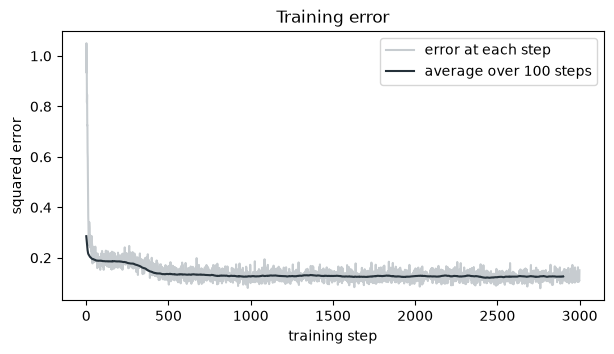

In [25]:
model = NoiseGuesser()
start = time.time()
errors = train(model, n_training_steps=3000)
print(f'Training done in {time.time() - start:.0f} s. Final error: {np.mean(errors[-200:]):.3f}')

plt.figure(figsize=(7, 3.5))
plt.plot(errors, color=GREY, alpha=0.4, label='error at each step')
plt.plot(np.convolve(errors, np.ones(100) / 100, mode='valid'), color=DARK, label='average over 100 steps')
plt.xlabel('training step'); plt.ylabel('squared error'); plt.legend(); plt.title('Training error')
plt.show()

**Question 5.** Describe the training curve. Does the error go down? Does it reach zero?

**Your answer:**

* The training error drops quickly at first, then decreases more gradually and levels off around 0.12. It does not reach zero; some error remains even after many training steps

**Question 6.** Even after a long training, the error does not reach zero. Why can't the network guess the noise perfectly? Use Question 4, *A known target does not mean a certain answer*.

**Your answer:**

* The noise cannot always be guessed perfectly because the same noisy point may have come from either group. In those ambiguous cases, the network can only make its best guess, so some error remains.

## 4 · Look at what the network has learned


For a given noise level, we can ask the network at **every** position of the plane: *which way should this point move to become less noisy?* (This is the opposite of the noise it guesses.) We draw the answer as an arrow. All the arrows together form a **field of directions**.

The coloured dots show where the centre of each group sits at that noise level. Adding noise fades everything towards the middle, so the dots move closer together when the noise level is high.

**Predict.** At a high noise level, where do you think most arrows will point? And at a low noise level?

**Your answer:**

* At a high noise level, the groups overlap, so most arrows should point toward the middle, where the data is concentrated. At a low noise level, the groups are easier to distinguish, so arrows should point toward the nearest group blue or pink.

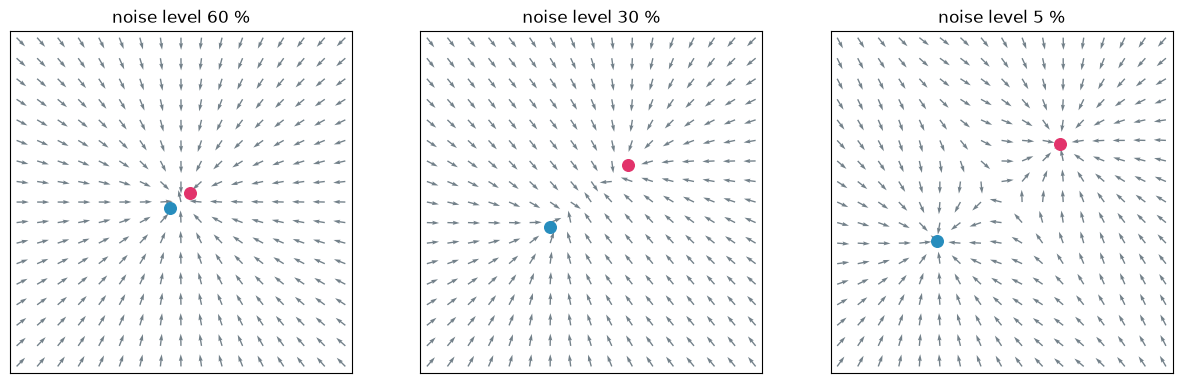

In [26]:
def show_arrows(model, level, ax, title=None):
    step = level_to_step(level)
    grid = torch.linspace(-2.5, 2.5, 17)
    X, Y = torch.meshgrid(grid, grid, indexing='xy')
    positions = torch.stack([X.flatten(), Y.flatten()], dim=1)
    with torch.no_grad():
        direction = -model(positions, torch.full((len(positions),), step))
    direction = direction / direction.norm(dim=1, keepdim=True)        # same length for every arrow
    ax.quiver(positions[:, 0], positions[:, 1], direction[:, 0], direction[:, 1],
              color=GREY, angles='xy', scale=28, width=0.004)
    fade = alpha_bar[step].sqrt()
    ax.scatter(*(fade * BLUE_CENTER), s=70, color=BLUE, zorder=3)
    ax.scatter(*(fade * PINK_CENTER), s=70, color=PINK, zorder=3)
    setup_axes(ax, title or f'noise level {int(level * 100)} %')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, level in zip(axes, [0.6, 0.3, 0.05]):
    show_arrows(model, level, ax)
plt.show()

**Question 7.** Describe the arrows at a high noise level (60 %) and at a low noise level (5 %). Where do they point?

**Your answer:**

* At 60 % noise, the arrows mostly point toward the middle, where the two groups overlap. At 5 % noise, they point toward the nearest group—blue or pink—because the groups are easier to distinguish

**Question 8.** At a high noise level, the arrows point towards the middle, between the two groups. Explain why, using your answer to Question 6.

**Your answer:**

* At high noise, the two groups overlap, so a point in the middle could have come from either group. The network cannot know which noise was added exactly, so it makes the best average guess.

### What if the network is not trained enough?

Let us train a second network for only 60 steps instead of 3000, and look at its arrows at a low noise level.

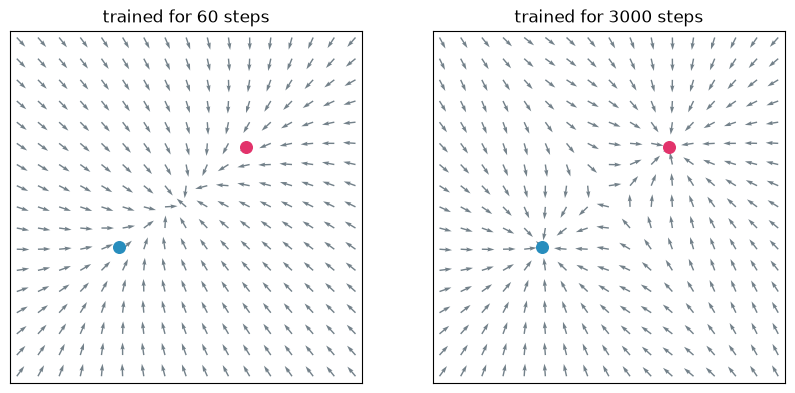

In [27]:
weak_model = NoiseGuesser()
train(weak_model, n_training_steps=60)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
show_arrows(weak_model, 0.05, axes[0], 'trained for 60 steps')
show_arrows(model, 0.05, axes[1], 'trained for 3000 steps')
plt.show()

**Question 9.** What is the difference between the two fields? What do you expect when we use the weak network to generate new points?

**Your answer:**

* The weak network’s arrows mostly point toward one central area, while the well-trained network’s arrows point toward each group separately.
So, using the weak network to generate points, I’d expect them to cluster in the middle instead of forming two clear groups.

## 5 · Generate new points, step by step

To **generate** a new point, we start from pure noise (100 %) and repeat:

1. **Predict**: ask the network for its guess at the current position and the current noise level.
2. **Update the state**: move the point a small step.
3. **Lower the noise level.**
4. **Predict again** from the new position.

During generation the network never sees a real point: it only follows its own arrows. The training weights do not change any more.

The function `generate` below has two settings that you will use in Part 6:

- `n_steps`: how many steps are used to go from 100 % to 0 %;
- `randomness`: whether a little fresh noise is added at each step.

In [28]:
@torch.no_grad()
def generate(model, n_points=500, n_steps=100, randomness=False, start_seed=0, randomness_seed=None, keep_paths=False):
    """Start from pure noise and apply the generation loop. Returns the final points (and the paths if asked)."""
    start_generator = torch.Generator().manual_seed(start_seed)
    x = torch.randn(n_points, 2, generator=start_generator)                    # pure noise
    if randomness_seed is None:
        randomness_seed = int(time.time() * 1e6) % 2**31
    step_generator = torch.Generator().manual_seed(randomness_seed)
    steps = torch.linspace(T - 1, 0, n_steps).round().long()                     # from 100 % down to 0 %
    paths = [x.clone()]
    for i, step in enumerate(steps):
        a_now = alpha_bar[step]
        a_next = alpha_bar[steps[i + 1]] if i + 1 < n_steps else torch.tensor(1.0)
        guess = model(x, step.repeat(n_points))                                  # 1. predict
        clean_estimate = (x - (1 - a_now).sqrt() * guess) / a_now.sqrt()
        extra = torch.tensor(0.0)
        if randomness and i + 1 < n_steps:
            extra = ((1 - a_next) / (1 - a_now)).sqrt() * (1 - a_now / a_next).sqrt()
        x = a_next.sqrt() * clean_estimate + (1 - a_next - extra ** 2).clamp(min=0).sqrt() * guess  # 2.-3. move, lower the level
        if randomness and i + 1 < n_steps:
            x = x + extra * torch.randn(x.shape, generator=step_generator)        # optional fresh noise
        if keep_paths:
            paths.append(x.clone())
    return (x, torch.stack(paths)) if keep_paths else x


def landing_report(points):
    """Share of the generated points that land on the blue group, on the pink group, or elsewhere."""
    on_blue = (points - BLUE_CENTER).norm(dim=1) < 3 * SPREAD
    on_pink = (points - PINK_CENTER).norm(dim=1) < 3 * SPREAD
    elsewhere = ~(on_blue | on_pink)
    return f'blue {on_blue.float().mean():.0%} · pink {on_pink.float().mean():.0%} · elsewhere {elsewhere.float().mean():.0%}'

Trained network: blue 48% · pink 48% · elsewhere 3%
Weak network:    blue 20% · pink 8% · elsewhere 71%


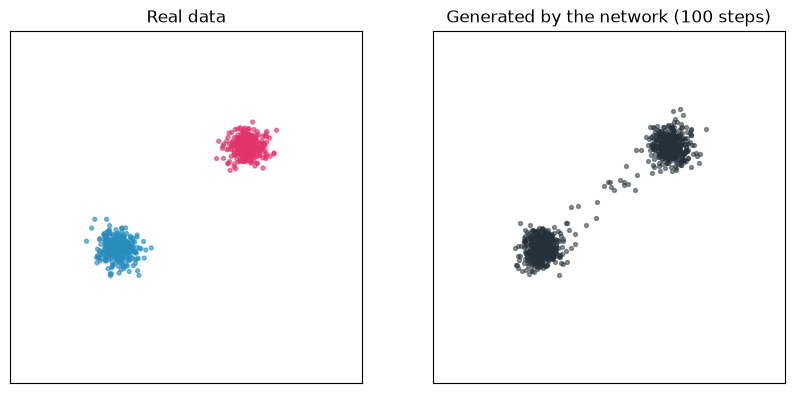

In [29]:
generated = generate(model, n_points=1000, n_steps=100)
print('Trained network:', landing_report(generated))
print('Weak network:   ', landing_report(generate(weak_model, n_points=1000, n_steps=100)))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
axes[0].scatter(real_points[:, 0], real_points[:, 1], s=8, c=kind_colors(real_kind), alpha=0.6)
setup_axes(axes[0], 'Real data')
axes[1].scatter(generated[:, 0], generated[:, 1], s=8, color=DARK, alpha=0.5)
setup_axes(axes[1], 'Generated by the network (100 steps)')
plt.show()

**Question 10.** Did the generated points land on both groups, in roughly which proportions? Did many points end up in the middle, between the groups? Compare with the weak network.

**Your answer:**

* The generated points form two groups, with roughly equal numbers in each. Only a few fall between them. Unlike the weak network, which tended to place points in the middle, the trained network reproduces both groups clearly.

Now let us follow 8 points during generation. The white circles are the starting points (pure noise).

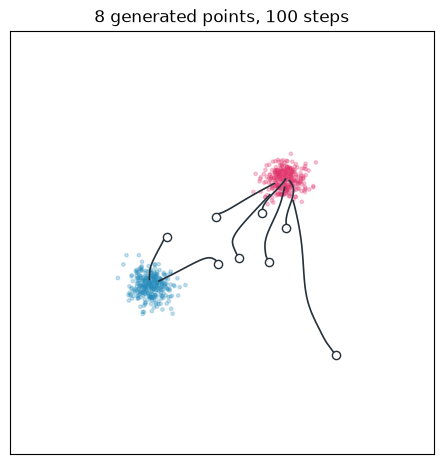

In [30]:
def show_paths(paths, ax, title, markers=False):
    ax.scatter(real_points[:, 0], real_points[:, 1], s=6, c=kind_colors(real_kind), alpha=0.25)
    for k in range(paths.shape[1]):
        ax.plot(paths[:, k, 0], paths[:, k, 1], color=DARK, lw=1.2, marker='o' if markers else None, ms=3)
        ax.scatter(paths[0, k, 0], paths[0, k, 1], facecolors='white', edgecolors=DARK, s=35, zorder=3)
    setup_axes(ax, title, lim=3)

_, paths = generate(model, n_points=8, n_steps=100, start_seed=3, keep_paths=True)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
show_paths(paths, ax, '8 generated points, 100 steps')
plt.show()

**Question 11.** Do the paths go in a straight line to a group? Describe their shape and explain it with the arrows of Part 4.

**Your answer:**

* No. The paths curve rather than going straight: at first they move toward the middle, then bend toward one of the two groups. This matches Part 4’s arrows, which point toward the middle at high noise and toward the groups as the noise decreases.

**Question 12.** Answer the question of slide 22 in your own words: the network predicts averages at high noise levels, so why do the generated points end **on** a group and not in the middle?

**Your answer:**

* At high noise, the network’s average prediction nudges points toward the middle. But generation happens step by step: as the noise decreases, the two groups become easier to distinguish, and the arrows guide each point toward one group or the other.

## 6 · Fewer steps, and the role of randomness



So far we used 100 steps. The original method (DDPM) uses **1000 steps** and adds **a little fresh noise at each step**. The DDIM method uses the same trained network, adds **no fresh noise**, and can **skip steps**. In our function:

- `randomness=True` → fresh noise at each step (DDPM style);
- `randomness=False` → no fresh noise (DDIM style).

### Fewer steps

**Predict.** With `randomness=False`, what will happen to the paths and to the share of points landing on the data with 1000, 50, 10 and only 3 steps?

**Your answer:**

* With no added randomness, the paths should be more direct. With 1000 or 50 steps, most points should still reach the data. With 10 steps, more may miss, and with only 3 steps, the paths may be too coarse, so fewer points will land on the groups.

1000 steps:  5.49 s for 2000 points · blue 50% · pink 47% · elsewhere 3%
  50 steps:  0.22 s for 2000 points · blue 50% · pink 47% · elsewhere 3%
  10 steps:  0.04 s for 2000 points · blue 48% · pink 44% · elsewhere 8%
   3 steps:  0.01 s for 2000 points · blue 19% · pink 3% · elsewhere 78%


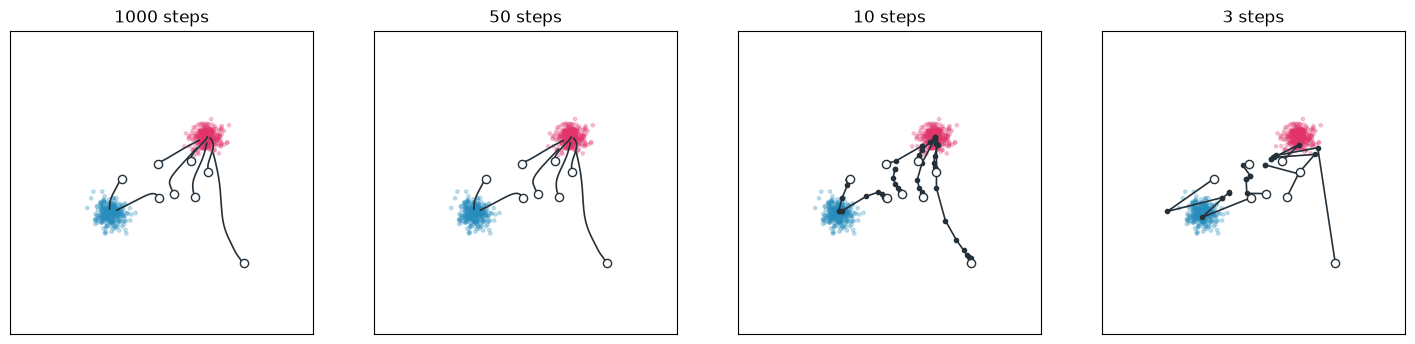

In [31]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for ax, n_steps in zip(axes, [1000, 50, 10, 3]):
    start = time.time()
    many = generate(model, n_points=2000, n_steps=n_steps, randomness=False)
    seconds = time.time() - start
    _, paths = generate(model, n_points=8, n_steps=n_steps, start_seed=3, keep_paths=True)
    show_paths(paths, ax, f'{n_steps} steps', markers=n_steps <= 10)
    print(f'{n_steps:4d} steps: {seconds:5.2f} s for 2000 points · {landing_report(many)}')
plt.show()

**Question 13.** What changes when the number of steps decreases: in the shape of the paths, in the time, and in the share of points landing on the data? Which number of steps would you choose, and why?

**Your answer:**

* As the number of steps decreases, the paths become less smooth and more abrupt. Generation is faster, but fewer points land on the groups especially with only 3 steps. I’d choose 50 steps: it is much faster than 1000 while still placing most points on the data.

### With or without randomness

We now start twice from **exactly the same** 500 noise points, and generate:

- twice **without** randomness;
- twice **with** randomness (a different fresh noise each time).

For each pair, we count how many points end in a different group.

**Predict.** In which case will the two runs give different results?

**Your answer:**

* The two runs should differ when randomness is added, because each run gets fresh noise at every step. Without added randomness, the same starting points and network should produce the same results.

In [32]:
def group_of(points):
    return ((points - PINK_CENTER).norm(dim=1) < (points - BLUE_CENTER).norm(dim=1)).long()   # 0 = blue, 1 = pink

for randomness in [False, True]:
    run_a = generate(model, n_points=500, n_steps=200, randomness=randomness, start_seed=7, randomness_seed=1)
    run_b = generate(model, n_points=500, n_steps=200, randomness=randomness, start_seed=7, randomness_seed=2)
    changed = (group_of(run_a) != group_of(run_b)).sum().item()
    print(f'randomness={randomness!s:5}: {changed} points out of 500 ended in a different group')

randomness=False: 0 points out of 500 ended in a different group
randomness=True : 255 points out of 500 ended in a different group


**Question 14.** Without randomness, what decides which group a point ends in? With randomness, what else plays a role?

**Your answer:**

* Without randomness, the starting noise point determines which group it reaches, following the network’s direction field. With randomness, the fresh noise added at each step can also change the path and the final group.

**Question 15.**, *The same words can produce different images*: what plays the role of the starting point in a text-to-image model?

**Your answer:**

* The starting point is the initial random noise. The text prompt guides how the model transforms that noise into an image, and a different starting noise can produce a different image from the same words.